1. Membaca dataset

In [3]:
import pandas as pd

data_buku = pd.read_csv("D:/Recommender-System/dataset/Books.csv", low_memory=False)
data_rating = pd.read_csv("D:/Recommender-System/dataset/Ratings.csv")
data_user = pd.read_csv("D:/Recommender-System/dataset/Users.csv")

print("1. Data buku")
display(data_buku)
print("2. Data rating")
display(data_rating)
print("3. Data user")
display(data_user)

1. Data buku


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...
...,...,...,...,...,...,...,...,...
271355,0440400988,There's a Bat in Bunk Five,Paula Danziger,1988,Random House Childrens Pub (Mm),http://images.amazon.com/images/P/0440400988.0...,http://images.amazon.com/images/P/0440400988.0...,http://images.amazon.com/images/P/0440400988.0...
271356,0525447644,From One to One Hundred,Teri Sloat,1991,Dutton Books,http://images.amazon.com/images/P/0525447644.0...,http://images.amazon.com/images/P/0525447644.0...,http://images.amazon.com/images/P/0525447644.0...
271357,006008667X,Lily Dale : The True Story of the Town that Ta...,Christine Wicker,2004,HarperSanFrancisco,http://images.amazon.com/images/P/006008667X.0...,http://images.amazon.com/images/P/006008667X.0...,http://images.amazon.com/images/P/006008667X.0...
271358,0192126040,Republic (World's Classics),Plato,1996,Oxford University Press,http://images.amazon.com/images/P/0192126040.0...,http://images.amazon.com/images/P/0192126040.0...,http://images.amazon.com/images/P/0192126040.0...


2. Data rating


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6
...,...,...,...
1149775,276704,1563526298,9
1149776,276706,0679447156,0
1149777,276709,0515107662,10
1149778,276721,0590442449,10


3. Data user


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN
...,...,...,...
278853,278854,"portland, oregon, usa",NaN
278854,278855,"tacoma, washington, united kingdom",50.0
278855,278856,"brampton, ontario, canada",NaN
278856,278857,"knoxville, tennessee, usa",NaN


2. Data understanding

In [4]:
data_buku.isnull().sum()

ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [5]:
data_buku.shape

(271360, 8)

In [6]:
 data_buku.nunique()

ISBN                   271360
Book-Title             242135
Book-Author            102022
Year-Of-Publication       118
Publisher               16807
Image-URL-S            271044
Image-URL-M            271044
Image-URL-L            271041
dtype: int64

In [7]:
# this means there is more than one ISBN number for a book
data_buku.groupby("Book-Title").agg({"ISBN":"count"}).sort_values("ISBN", ascending=False).head(10)

,ISBN
Book-Title,
Selected Poems,27
Little Women,24
Wuthering Heights,21
Adventures of Huckleberry Finn,20
Dracula,20
The Secret Garden,20
Jane Eyre,19
The Night Before Christmas,18
Pride and Prejudice,18


In [8]:
# combine these two dataframes
merged_df=data_buku.merge(data_rating, how="left", on="ISBN")

In [9]:
# we see that the presentage of 0 given to some books s quite high.
merged_df["Book-Rating"].value_counts()

Book-Rating
0.0     647294
8.0      91804
10.0     71225
7.0      66402
9.0      60778
5.0      45355
6.0      31687
4.0       7617
3.0       5118
2.0       2375
1.0       1481
Name: count, dtype: int64

In [11]:
# How many books has a user commented? let's look at the 10 users who commented the most
merged_df.groupby("User-ID").agg({"Book-Title":"count"}).sort_values("Book-Title",ascending=False).head(10)

,Book-Title
User-ID,
11676.0,11144
198711.0,6456
153662.0,5814
98391.0,5779
35859.0,5646
212898.0,4289
278418.0,3996
76352.0,3329
110973.0,2971


In [12]:
# What are the most commented books?
merged_df.groupby("Book-Title").agg({"Book-Rating":"count"}).sort_values("Book-Rating", ascending=False).head(5)

,Book-Rating
Book-Title,
Wild Animus,2502
The Lovely Bones: A Novel,1295
The Da Vinci Code,898
A Painted House,838
The Nanny Diaries: A Novel,828


In [13]:
new=merged_df.groupby("Book-Title").agg({"Book-Rating":["count","mean"]}) 
new.head(5)

Book-Rating      
                                                         count  mean
Book-Title                                                          
A Light in the Storm: The Civil War Diary of Am...           4  2.25
Always Have Popsicles                                        1  0.00
Apple Magic (The Collector's series)                         1  0.00
Ask Lily (Young Women of Faith: Lily Series, Bo...           1  8.00
Beyond IBM: Leadership Marketing and Finance fo...           1  0.00

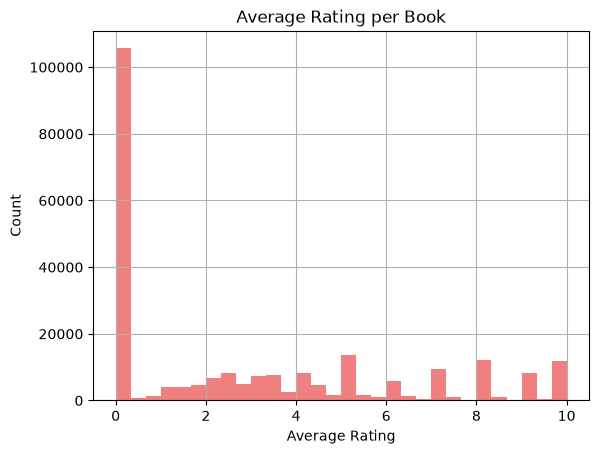

In [14]:
import matplotlib.pyplot as plt
avg_rating_per_book = merged_df.groupby('Book-Title')['Book-Rating'].mean()
avg_rating_per_book.hist(bins=30, color='lightcoral')
plt.title('Average Rating per Book')
plt.xlabel('Average Rating')
plt.ylabel('Count')
plt.show()

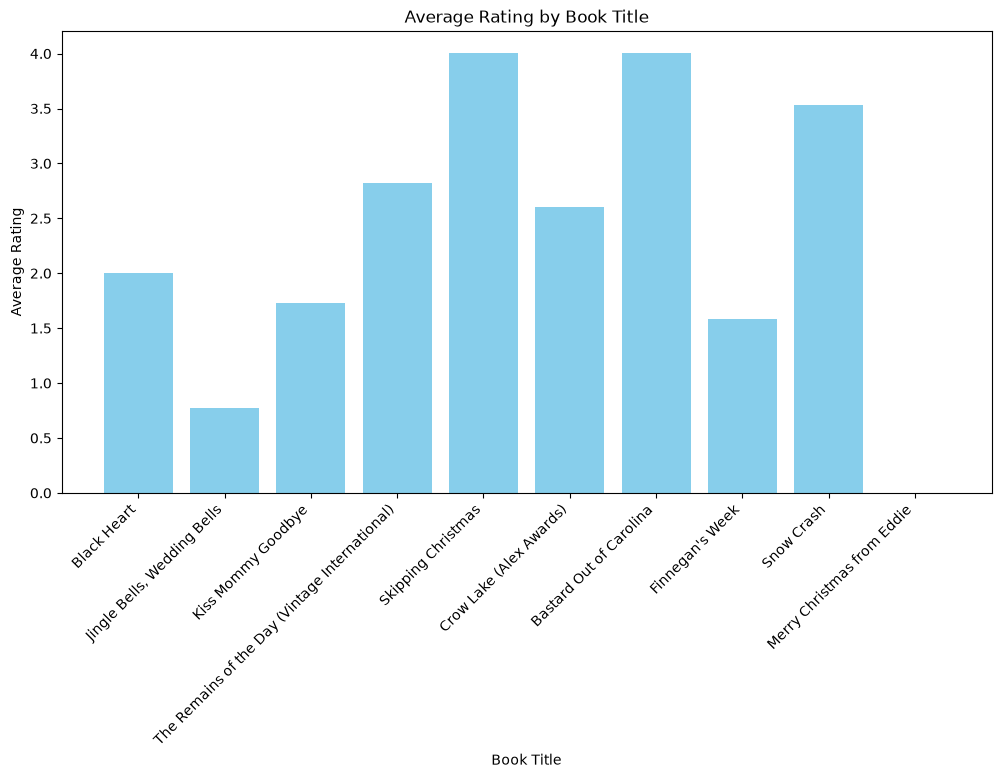

In [16]:
import matplotlib.pyplot as plt
import numpy as np

sample_book = merged_df['Book-Title'].sample(10)
average_ratings = [merged_df[merged_df['Book-Title'] == book]['Book-Rating'].mean() for book in sample_book]

plt.figure(figsize=(12, 6))
plt.bar(sample_book, average_ratings, color='skyblue')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Book Title')
plt.ylabel('Average Rating')
plt.title('Average Rating by Book Title')


plt.show()

In [17]:
merged_df[merged_df["Book-Title"]=="The Open Door"][["Book-Rating"]]

,Book-Rating
912250,0.0


In [18]:
# How many people have read the books reviewed with an average rating of 0 or 2?
new=merged_df.groupby("Book-Title").agg({"Book-Rating":["count","mean"]})  
new=new.droplevel(0, axis=1)
new.head()

,count,mean
Book-Title,,
"A Light in the Storm: The Civil War Diary of Amelia Martin, Fenwick Island, Delaware, 1861 (Dear America)",4,2.25
Always Have Popsicles,1,0.00
Apple Magic (The Collector's series),1,0.00
"Ask Lily (Young Women of Faith: Lily Series, Book 5)",1,8.00
Beyond IBM: Leadership Marketing and Finance for the 1990s,1,0.00
